# 🚗⚡ Electric Vehicle (EV) Battery Failure Prediction & Prognostics
## Comprehensive Exploratory Data Analysis (EDA) and Machine Learning Workflow

---

### 📋 Project Overview & Problem Statement
Lithium-ion batteries are the single most critical, expensive, and safety-sensitive component of modern Electric Vehicles (EVs). Battery failure can lead to severe operational downtime, expensive warranty replacements, decreased vehicle longevity, and in critical scenarios, catastrophic thermal runaway events.

**Objectives:**
1. **In-depth Exploratory Data Analysis (EDA)**: Understand the structural relationships between battery chemistry, operational usage (odometer, cycle count, fast charging), thermal dynamics, and battery degradation indicators.
2. **Data Preprocessing & Feature Engineering**: Handle missing values, encode categorical variables, and engineer domain-specific battery stress, thermal load, and cycling indicators.
3. **Machine Learning Predictive Modeling**: Train, evaluate, and benchmark multiple machine learning algorithms (`Logistic Regression`, `Gaussian Naive Bayes`, `Decision Tree`, `Random Forest`, `XGBoost`) to accurately detect and predict battery failure.
4. **Model Evaluation & Interpretation**: Evaluate models using Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, Confusion Matrices, and Feature Importance analysis.
5. **Threshold Optimization & Operational Recommendations**: Provide actionable insights for Battery Management Systems (BMS) and fleet operations.

## 1. Environment Setup & Library Imports
We import essential libraries for data manipulation (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), preprocessing, and machine learning (`scikit-learn`, `xgboost`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

# Machine Learning Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Visualization aesthetics configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("✓ All libraries imported successfully.")

✓ All libraries imported successfully.


## 2. Data Ingestion & Initial Exploration
Let's load the dataset `ev_battery_failure_dataset.csv` and inspect its shape, structure, features, datatypes, and initial statistics.

In [2]:
# Load the EV battery failure dataset
df = pd.read_csv('ev_battery_failure_dataset.csv')

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print("\n--- First 5 Rows ---")
df.head()

Dataset Shape: 200,000 rows, 70 columns

--- First 5 Rows ---


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


In [3]:
# Dataset info and column types overview
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  str    
 1   vehicle_brand                    193564 non-null  str    
 2   vehicle_model                    191796 non-null  str    
 3   vehicle_type                     193568 non-null  str    
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  str    
 6   battery_chemistry                192786 non-null  str    
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  str    
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  str    
 12  battery_seria

In [4]:
# Statistical summary of numerical features
df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
manufacturing_year,2019.501333,2.873497,2015.00000,2017.000000,2020.00000,2022.00000,2024.00000
battery_capacity_kwh,76.236405,21.302330,25.00000,60.980000,75.35000,89.99000,149.01000
odometer_km,102822.193327,87965.819977,500.00000,36128.000000,78919.00000,146010.75000,450000.00000
vehicle_age_years,6.495245,2.878180,1.37000,4.000000,6.34000,9.00000,11.55000
cycle_count,296.383934,282.614453,1.00000,95.000000,218.00000,412.00000,3369.00000
battery_health_percent,87.381787,12.540742,21.42000,80.990000,91.12000,97.43000,99.80000
state_of_charge,54.847079,21.450372,2.00000,40.070000,54.94000,69.78000,100.00000
depth_of_discharge,38.290397,12.754524,5.00000,29.600000,38.28000,46.91000,92.03000
state_of_health,87.297020,12.527256,21.80000,80.910000,91.05000,97.33000,100.00000
cell_voltage_avg,3.288515,0.246766,2.04850,3.106025,3.35580,3.46390,3.85300


## 3. Data Cleaning & Handling Missing Values
In this step, we:
1. Identify and drop non-predictive identifier columns (`vehicle_id`, `battery_serial`).
2. Analyze the extent of missing values across all features.
3. Impute missing values using robust statistical strategies:
   - **Numerical columns**: Median imputation (robust against skewed telemetry and outliers).
   - **Categorical columns**: Mode imputation (most frequent category).
4. Verify duplicate records.

In [5]:
# Check for duplicate rows
print(f"Duplicate rows count: {df.duplicated().sum()}")

# Drop unique identifier columns
identifiers = ['vehicle_id', 'battery_serial']
df_clean = df.drop(columns=[col for col in identifiers if col in df.columns])
print(f"Features after dropping identifiers: {df_clean.shape[1]}")

Duplicate rows count: 0
Features after dropping identifiers: 68


In [6]:
# Missing values summary
missing_counts = df_clean.isnull().sum()
missing_percent = (missing_counts / len(df_clean)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Missing_Percent': missing_percent})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Percent', ascending=False)

print(f"Total columns with missing values: {len(missing_df)}")
print("\nTop 10 features with highest missing percentage:")
missing_df.head(10)

Total columns with missing values: 67

Top 10 features with highest missing percentage:


,Missing_Count,Missing_Percent
fast_charge_ratio,9879,4.9395
average_speed,9849,4.9245
manufacturing_year,9829,4.9145
home_charging_ratio,9805,4.9025
sensor_fault_count,9674,4.8370
charging_interruptions,9648,4.8240
state_of_charge,9636,4.8180
state_of_health,9565,4.7825
capacity_loss_percent,9559,4.7795
slow_charge_ratio,9483,4.7415


In [7]:
# Impute missing values
num_cols = df_clean.select_dtypes(include=[np.number]).columns.drop('battery_failure')
cat_cols = df_clean.select_dtypes(include=['object', 'str']).columns

# Numerical imputation: Median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical imputation: Mode
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Remaining null values in dataset: {df_clean.isnull().sum().sum()}")

Remaining null values in dataset: 0


## 4. In-Depth Exploratory Data Analysis (EDA)
We conduct targeted visualizations and statistical checks across key domains:
- **Class Balance**: Battery failure distribution
- **Battery Chemistry & Degradation Dynamics**
- **Operational & Fleet Factors**
- **Thermal & Voltage Instability**
- **Charging Behaviors**
- **Feature Correlations**

### 4.1 Target Variable Analysis: `battery_failure`
Analyzing the proportion of failed vs healthy batteries in the dataset.

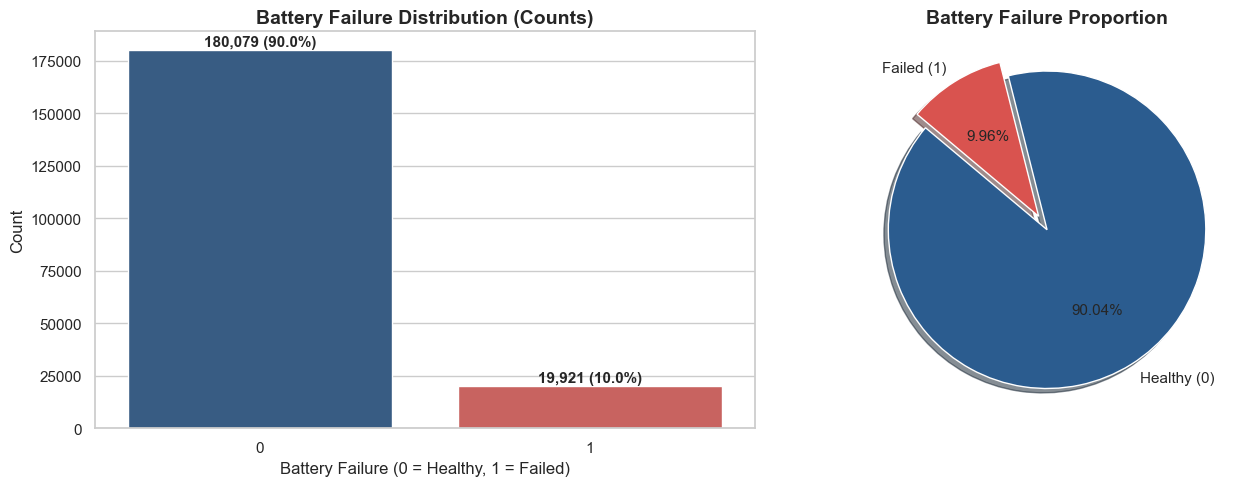

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
counts = df_clean['battery_failure'].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=['#2b5c8f', '#d9534f'])
axes[0].set_title("Battery Failure Distribution (Counts)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Battery Failure (0 = Healthy, 1 = Failed)")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 2000, f"{v:,} ({v/len(df_clean):.1%})", ha='center', fontweight='bold')

# Pie Chart
axes[1].pie(counts.values, labels=['Healthy (0)', 'Failed (1)'], autopct='%1.2f%%',
           colors=['#2b5c8f', '#d9534f'], explode=(0, 0.1), startangle=140, shadow=True)
axes[1].set_title("Battery Failure Proportion", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 4.2 Battery Chemistry & Fleet Type Impact on Failure Rate
Comparing failure rates across battery chemistries (NMC, LFP, NCA, LMO, LTO) and operational usage (Fleet vs Private).

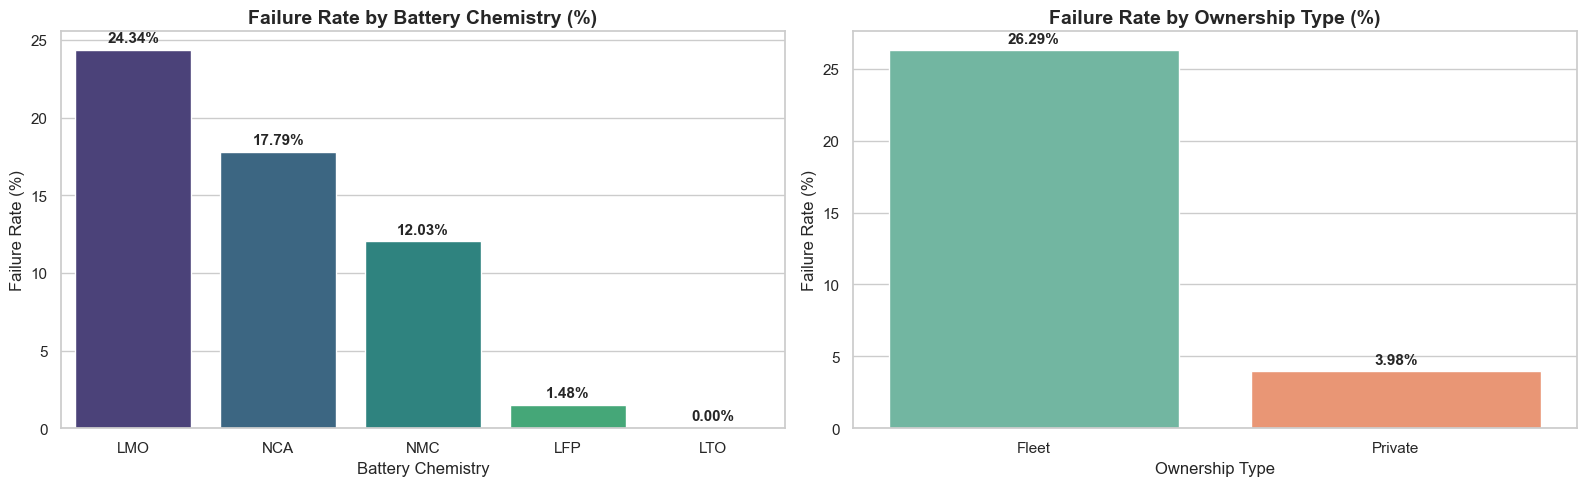

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Battery Chemistry Failure Rate
chem_failure = df_clean.groupby('battery_chemistry')['battery_failure'].mean().sort_values(ascending=False) * 100
sns.barplot(x=chem_failure.index, y=chem_failure.values, ax=axes[0], palette='viridis')
axes[0].set_title("Failure Rate by Battery Chemistry (%)", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Failure Rate (%)")
axes[0].set_xlabel("Battery Chemistry")
for i, v in enumerate(chem_failure.values):
    axes[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# Fleet vs Private Failure Rate
fleet_failure = df_clean.groupby('fleet_or_private')['battery_failure'].mean().sort_values(ascending=False) * 100
sns.barplot(x=fleet_failure.index, y=fleet_failure.values, ax=axes[1], palette='Set2')
axes[1].set_title("Failure Rate by Ownership Type (%)", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Failure Rate (%)")
axes[1].set_xlabel("Ownership Type")
for i, v in enumerate(fleet_failure.values):
    axes[1].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 4.3 Degradation & State of Health (SOH) Analysis
Examining how `battery_health_percent`, `state_of_health`, and `capacity_loss_percent` differ between healthy and failing packs.

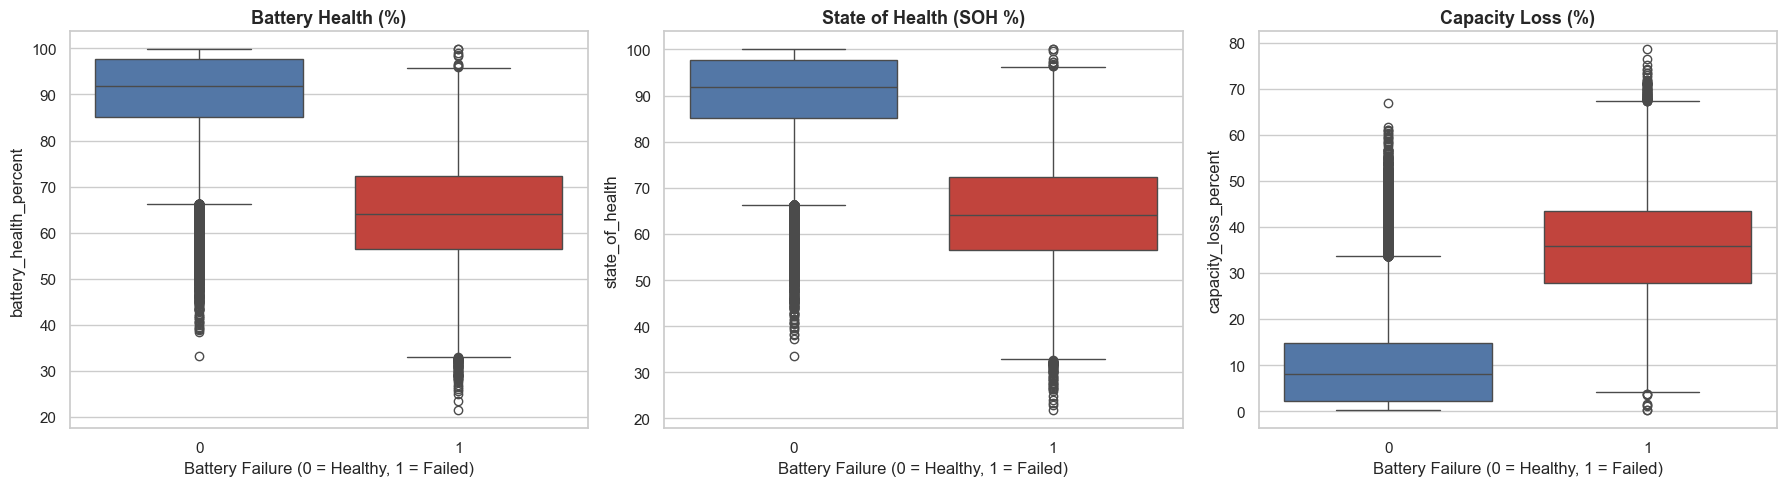

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features_health = ['battery_health_percent', 'state_of_health', 'capacity_loss_percent']
titles = ['Battery Health (%)', 'State of Health (SOH %)', 'Capacity Loss (%)']

for i, col in enumerate(features_health):
    sns.boxplot(x='battery_failure', y=col, data=df_clean, ax=axes[i], palette=['#4575b4', '#d73027'])
    axes[i].set_title(titles[i], fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Battery Failure (0 = Healthy, 1 = Failed)")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

### 4.4 Thermal & Voltage Instability Dynamics
Analyzing critical risk signals: `cell_voltage_std`, `voltage_imbalance`, `thermal_runaway_risk`, and `internal_resistance`.

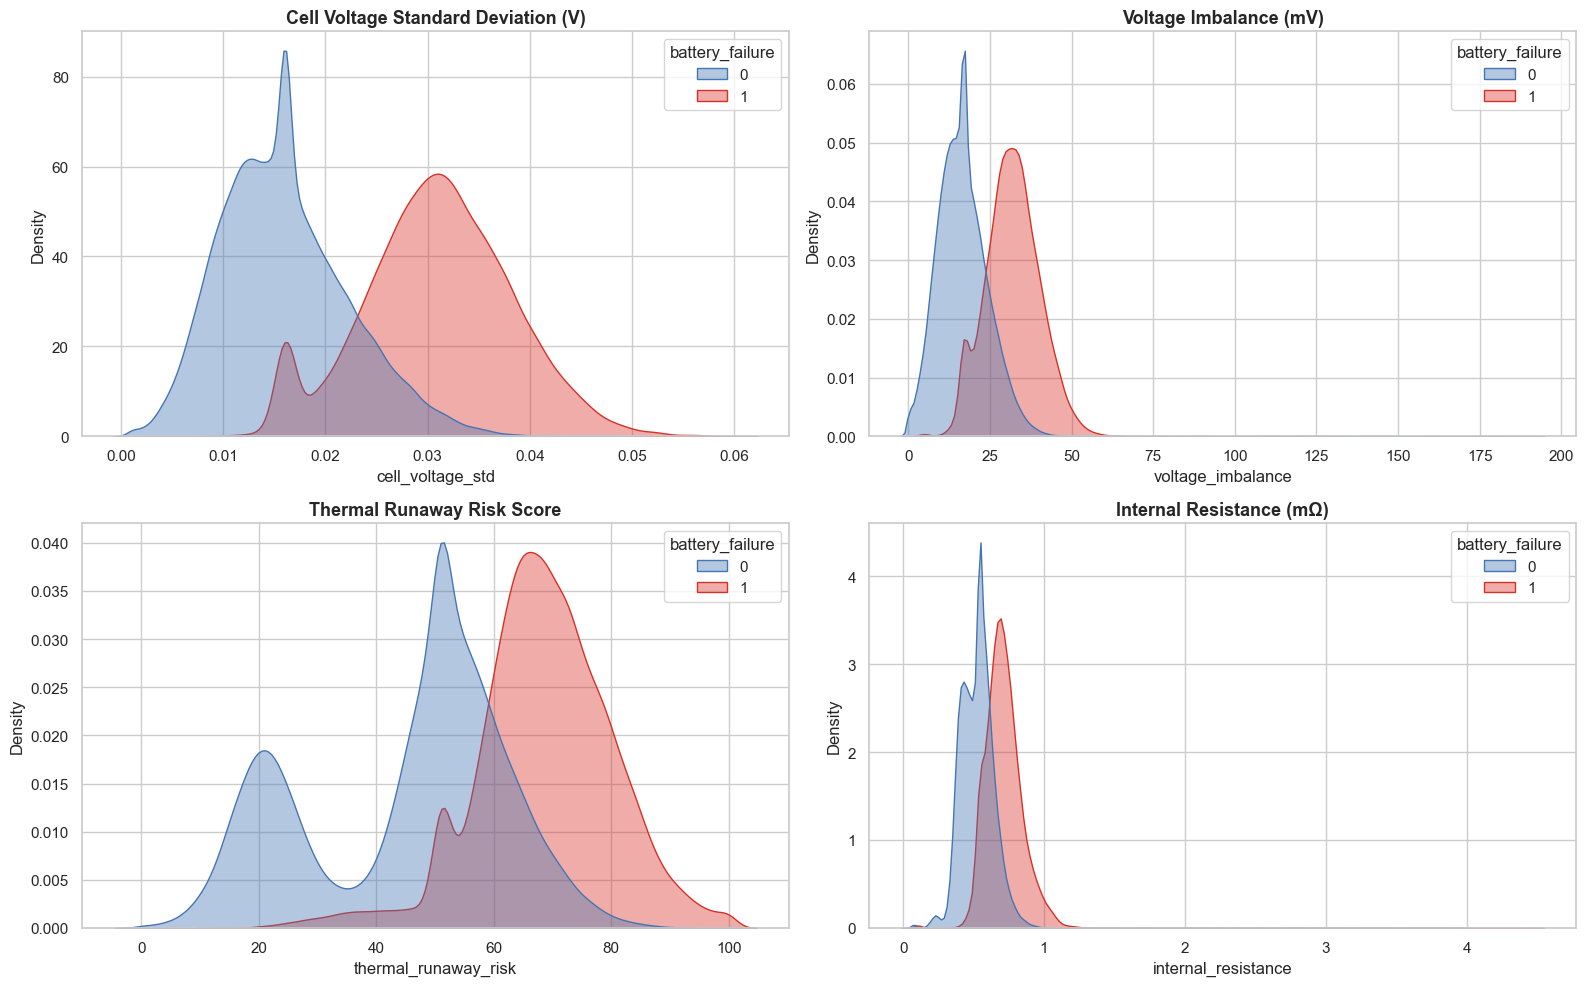

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

risk_cols = ['cell_voltage_std', 'voltage_imbalance', 'thermal_runaway_risk', 'internal_resistance']
risk_titles = [
    'Cell Voltage Standard Deviation (V)',
    'Voltage Imbalance (mV)',
    'Thermal Runaway Risk Score',
    'Internal Resistance (mΩ)'
]

for idx, (col, title) in enumerate(zip(risk_cols, risk_titles)):
    r, c = idx // 2, idx % 2
    sns.kdeplot(data=df_clean, x=col, hue='battery_failure', common_norm=False, fill=True, ax=axes[r, c], palette=['#4575b4', '#d73027'], alpha=0.4)
    axes[r, c].set_title(title, fontsize=13, fontweight='bold')
    axes[r, c].set_xlabel(col)

plt.tight_layout()
plt.show()

### 4.5 Mileage, Cycling & Charging Profiles
Investigating the interplay of `cycle_count`, `odometer_km`, and fast charging on failure incidence.

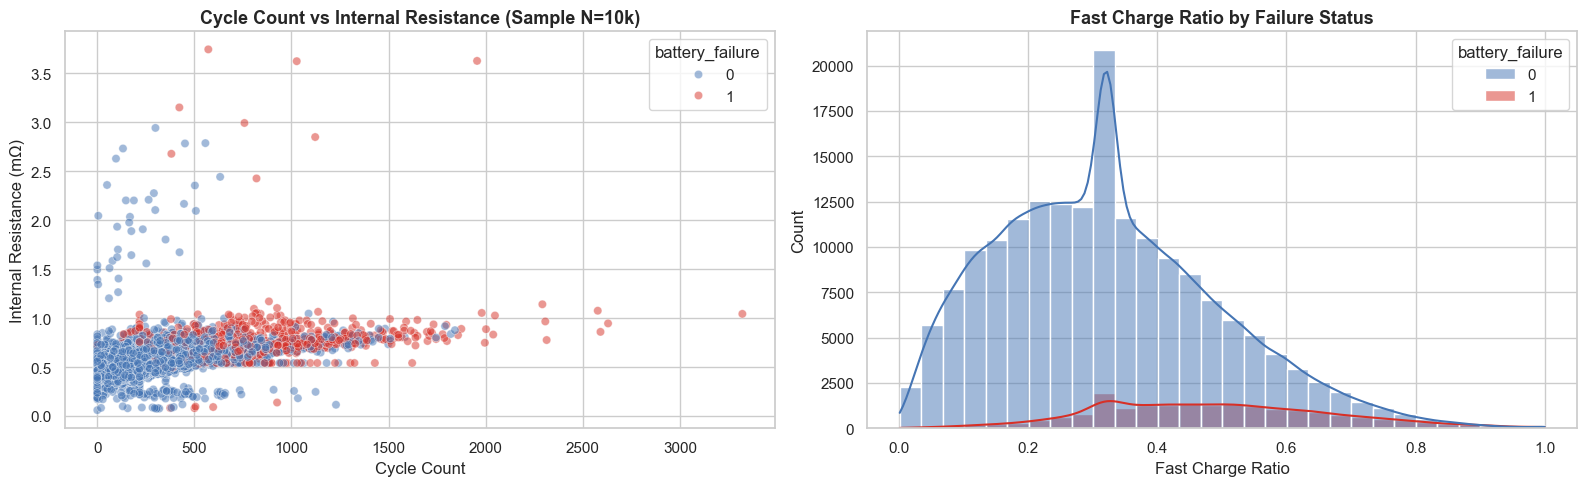

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Cycle Count vs Internal Resistance colored by Battery Failure
sample_df = df_clean.sample(n=10000, random_state=42)
sns.scatterplot(
    data=sample_df, x='cycle_count', y='internal_resistance',
    hue='battery_failure', alpha=0.5, palette=['#4575b4', '#d73027'], ax=axes[0]
)
axes[0].set_title("Cycle Count vs Internal Resistance (Sample N=10k)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Cycle Count")
axes[0].set_ylabel("Internal Resistance (mΩ)")

# Fast Charge Ratio Distribution
sns.histplot(data=df_clean, x='fast_charge_ratio', hue='battery_failure', bins=30, kde=True, ax=axes[1], palette=['#4575b4', '#d73027'])
axes[1].set_title("Fast Charge Ratio by Failure Status", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Fast Charge Ratio")

plt.tight_layout()
plt.show()

### 4.6 Correlation Matrix: Top Predictors of Battery Failure
Identifying features exhibiting the highest positive and negative linear correlations with the target variable `battery_failure`.

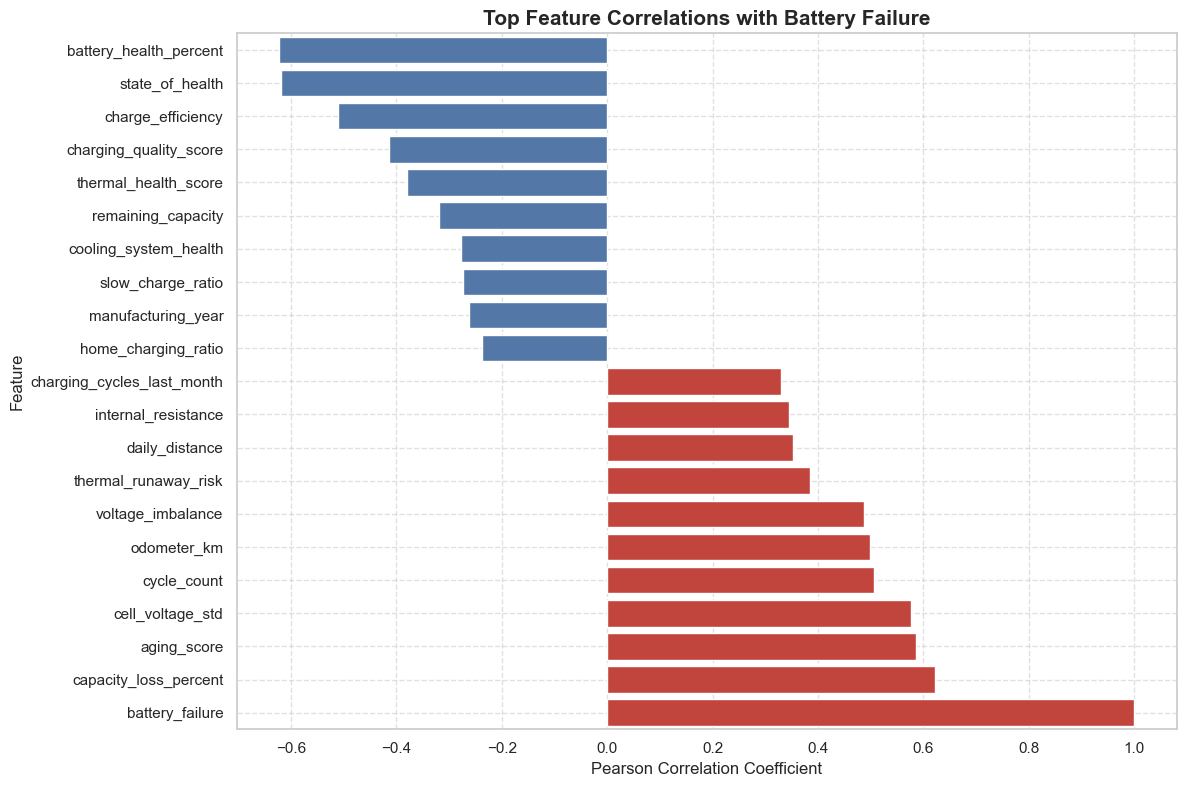

In [13]:
num_df = df_clean.select_dtypes(include=[np.number])
correlations = num_df.corr()['battery_failure'].sort_values()

# Top 10 negative and top 10 positive correlated features
top_corr_features = pd.concat([correlations.head(10), correlations.tail(11)])

plt.figure(figsize=(12, 8))
colors = ['#d73027' if x > 0 else '#4575b4' for x in top_corr_features.values]
sns.barplot(x=top_corr_features.values, y=top_corr_features.index, palette=colors)
plt.title("Top Feature Correlations with Battery Failure", fontsize=15, fontweight='bold')
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Feature")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5. Domain-Specific Feature Engineering
Based on electrochemical and telemetry dynamics, we construct high-leverage composite features:
1. `thermal_stress_product`: Product of maximum cell temperature and internal resistance (proxy for Joule heating load: $P = I^2 R \propto T_{max} \cdot R_{int}$).
2. `cycling_intensity`: Average charge/discharge cycles accumulated per vehicle year.
3. `fast_charge_exposure`: Product of fast charge ratio and monthly charging frequency.
4. `voltage_risk_index`: Combined metric of cell-to-cell voltage variance and pack voltage imbalance.
5. `effective_degradation_rate`: Capacity loss normalized by accumulated mileage.

In [14]:
# Engineer composite domain features
df_feat = df_clean.copy()

df_feat['thermal_stress_product'] = df_feat['cell_temperature_max'] * df_feat['internal_resistance']
df_feat['cycling_intensity'] = df_feat['cycle_count'] / (df_feat['vehicle_age_years'] + 0.1)
df_feat['fast_charge_exposure'] = df_feat['fast_charge_ratio'] * df_feat['charging_cycles_last_month']
df_feat['voltage_risk_index'] = df_feat['cell_voltage_std'] * df_feat['voltage_imbalance']
df_feat['effective_degradation_rate'] = df_feat['capacity_loss_percent'] / ((df_feat['odometer_km'] / 1000) + 1)

print(f"Features count after engineering: {df_feat.shape[1]}")
df_feat[['thermal_stress_product', 'cycling_intensity', 'fast_charge_exposure', 'voltage_risk_index', 'effective_degradation_rate']].head()

Features count after engineering: 73


,thermal_stress_product,cycling_intensity,fast_charge_exposure,voltage_risk_index,effective_degradation_rate
0,-6.611340,35.511364,0.824,0.279837,0.266127
1,17.856580,32.446134,1.251,0.142996,0.124171
2,19.245495,69.937107,4.368,0.302892,0.113585
3,2.590000,54.813665,4.170,0.197188,0.175797
4,17.668560,25.556545,1.250,0.533872,0.140337


## 6. Categorical Encoding & Train/Test Partitioning
We apply One-Hot Encoding (`pd.get_dummies(..., drop_first=True)`) to convert nominal categorical features into numeric format and split into stratified training (80%) and testing (20%) partitions.

In [15]:
# One-hot encode categorical features
cat_cols = df_feat.select_dtypes(include=['object', 'str']).columns
df_encoded = pd.get_dummies(df_feat, columns=cat_cols, drop_first=True)

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['battery_failure'])
y = df_encoded['battery_failure']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train class ratio: 0={sum(y_train==0)/len(y_train):.1%}, 1={sum(y_train==1)/len(y_train):.1%}")
print(f"y_test class ratio:  0={sum(y_test==0)/len(y_test):.1%}, 1={sum(y_test==1)/len(y_test):.1%}")

X_train shape: (160000, 161)
X_test shape:  (40000, 161)
y_train class ratio: 0=90.0%, 1=10.0%
y_test class ratio:  0=90.0%, 1=10.0%


In [16]:
# Feature scaling for linear and distance-based models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✓ Feature scaling complete.")

✓ Feature scaling complete.


## 7. Machine Learning Model Training & Benchmarking
We train and systematically evaluate 5 classification algorithms:
1. **Logistic Regression (Standardized baseline)**
2. **Gaussian Naive Bayes**
3. **Decision Tree Classifier**
4. **Random Forest Classifier**
5. **XGBoost Classifier (Extreme Gradient Boosting)**

Each model is evaluated across multiple standard classification metrics:
- **Accuracy**: Overall prediction correctness.
- **Precision**: Proportion of predicted failures that were true failures ($TP / (TP + FP)$).
- **Recall (Sensitivity)**: Proportion of actual failures successfully caught ($TP / (TP + FN)$).
- **F1-Score**: Harmonic mean of Precision and Recall.
- **ROC-AUC**: Area Under the Receiver Operating Characteristic Curve.
- **PR-AUC**: Area Under the Precision-Recall Curve.

In [17]:
# Define model instances
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss')
}

# Container for storing evaluation metrics and prediction results
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    print(f"Training {name}...")
    
    # Train using scaled data for Logistic Regression / Naive Bayes, raw data for Tree models
    if name in ['Logistic Regression', 'Gaussian Naive Bayes']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

# Compile results dataframe
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("\n=== Model Performance Benchmark Summary ===")
results_df

Training Logistic Regression...


Training Gaussian Naive Bayes...


Training Decision Tree...


Training Random Forest...


Training XGBoost...



=== Model Performance Benchmark Summary ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.966400,0.851064,0.803213,0.826446,0.989315,0.922426
1,XGBoost,0.965675,0.849531,0.796436,0.822127,0.988924,0.918652
2,Random Forest,0.957750,0.839349,0.712098,0.770505,0.983722,0.885511
3,Decision Tree,0.953825,0.797384,0.719127,0.756236,0.972659,0.833361
4,Gaussian Naive Bayes,0.810925,0.337922,0.936496,0.496639,0.933268,0.561361


## 8. Model Evaluation & Comparative Visualizations
Visualizing benchmark metrics, Confusion Matrices, ROC Curves, and Precision-Recall Curves.

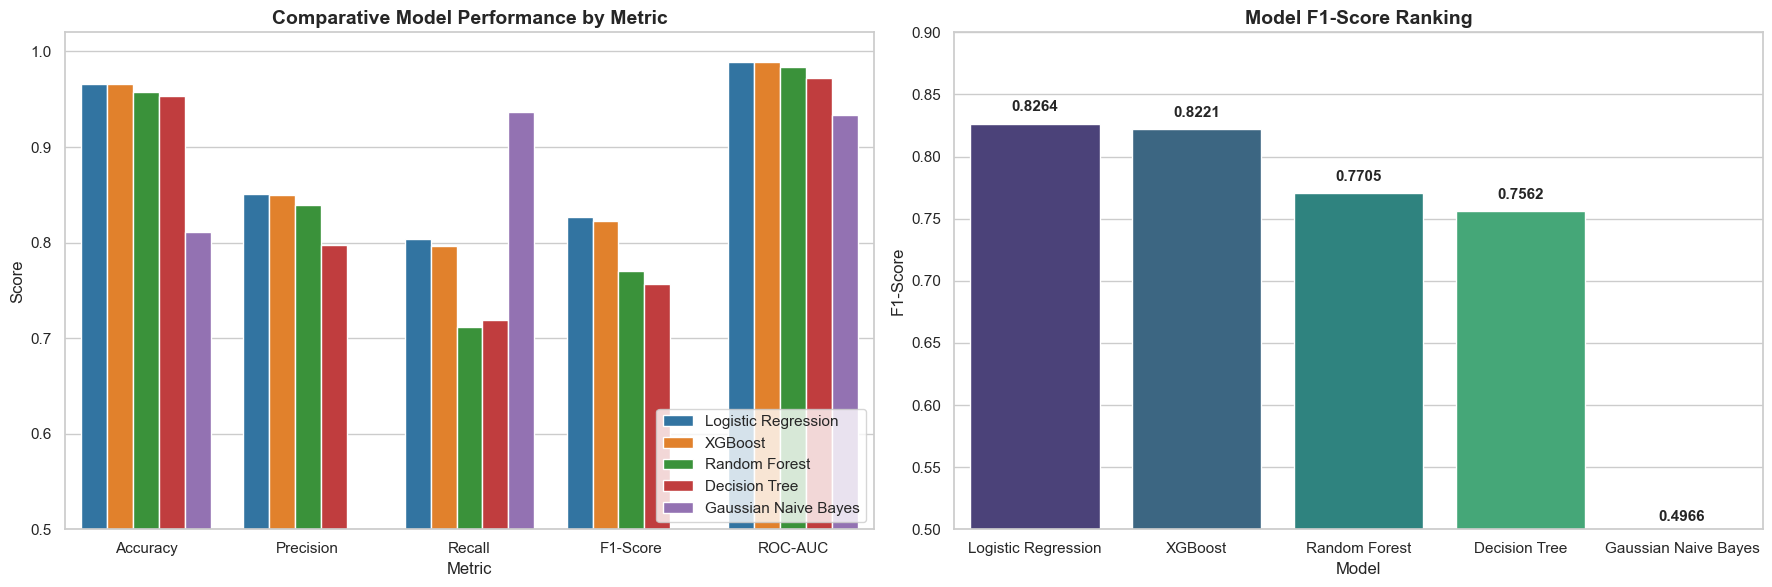

In [18]:
# Benchmark Metric Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
results_melted = results_df.melt(id_vars='Model', value_vars=metrics_to_plot, var_name='Metric', value_name='Score')

sns.barplot(data=results_melted, x='Metric', y='Score', hue='Model', ax=axes[0], palette='tab10')
axes[0].set_title("Comparative Model Performance by Metric", fontsize=14, fontweight='bold')
axes[0].set_ylim(0.5, 1.02)
axes[0].legend(loc='lower right')

# F1-Score & ROC-AUC Focus
sns.barplot(data=results_df, x='Model', y='F1-Score', ax=axes[1], palette='viridis')
axes[1].set_title("Model F1-Score Ranking", fontsize=14, fontweight='bold')
axes[1].set_ylim(0.5, 0.9)
for i, v in enumerate(results_df['F1-Score']):
    axes[1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

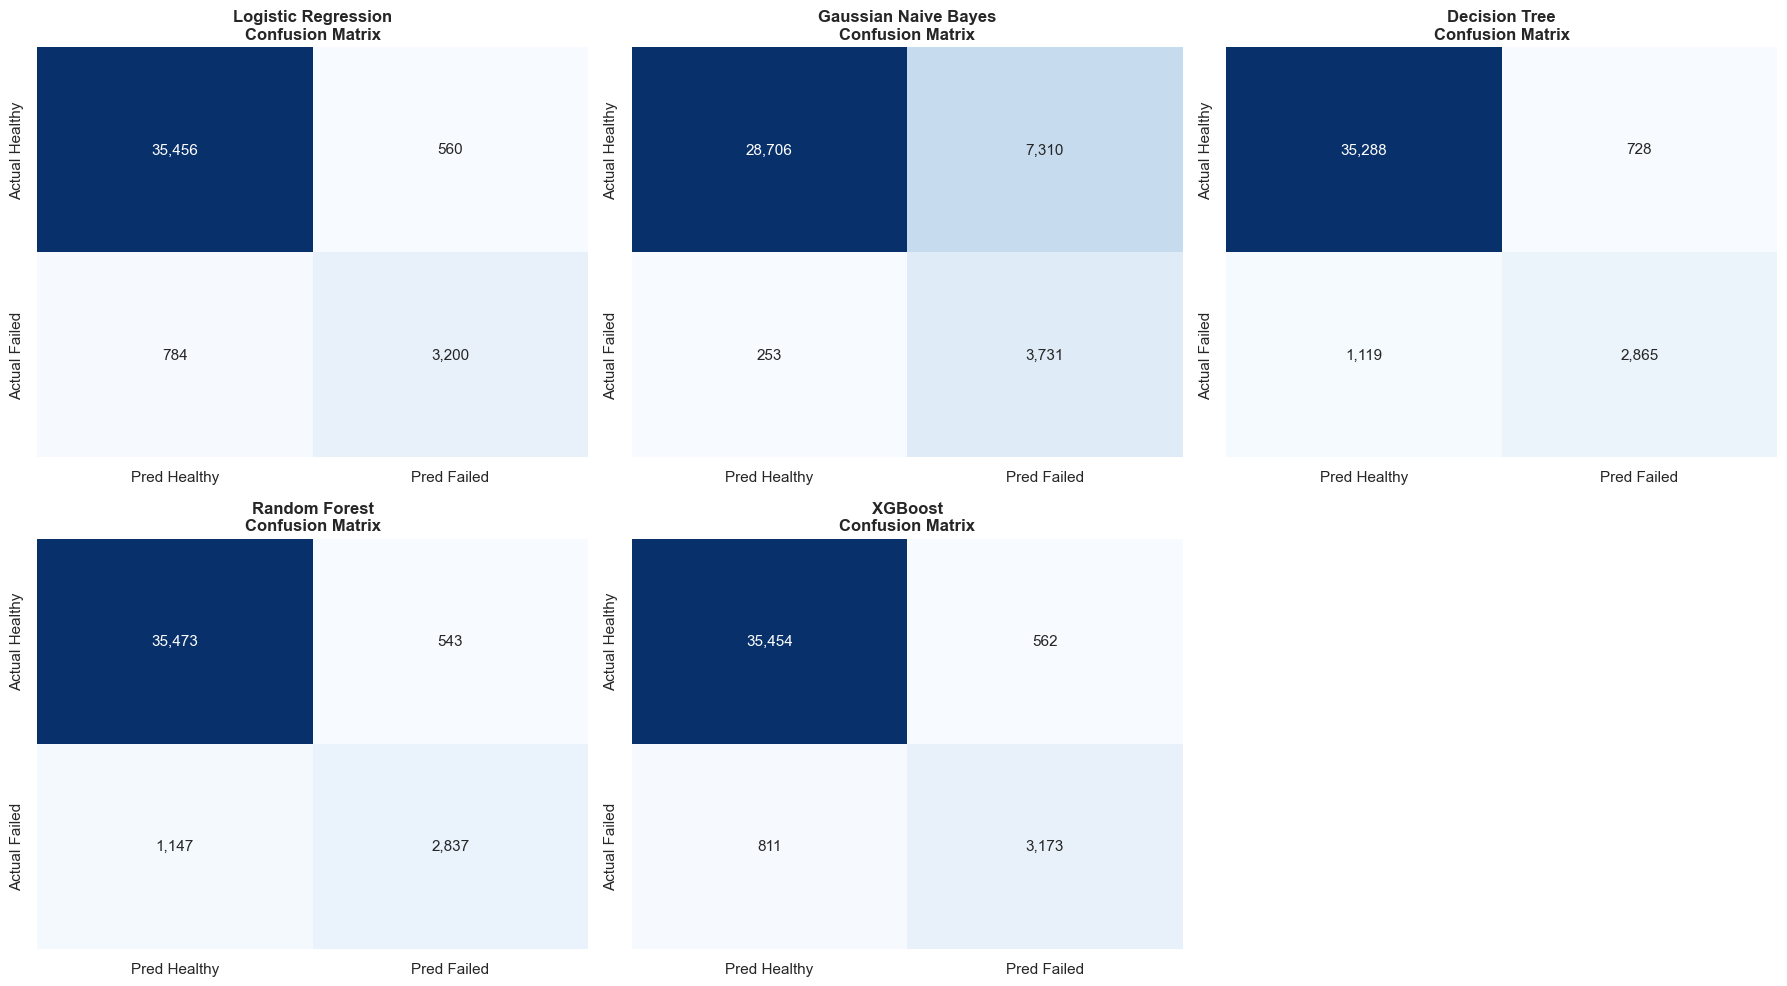

In [19]:
# Confusion Matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes_flat[idx], cbar=False,
                xticklabels=['Pred Healthy', 'Pred Failed'],
                yticklabels=['Actual Healthy', 'Actual Failed'])
    axes_flat[idx].set_title(f"{name}\nConfusion Matrix", fontsize=12, fontweight='bold')

axes_flat[-1].axis('off')
plt.tight_layout()
plt.show()

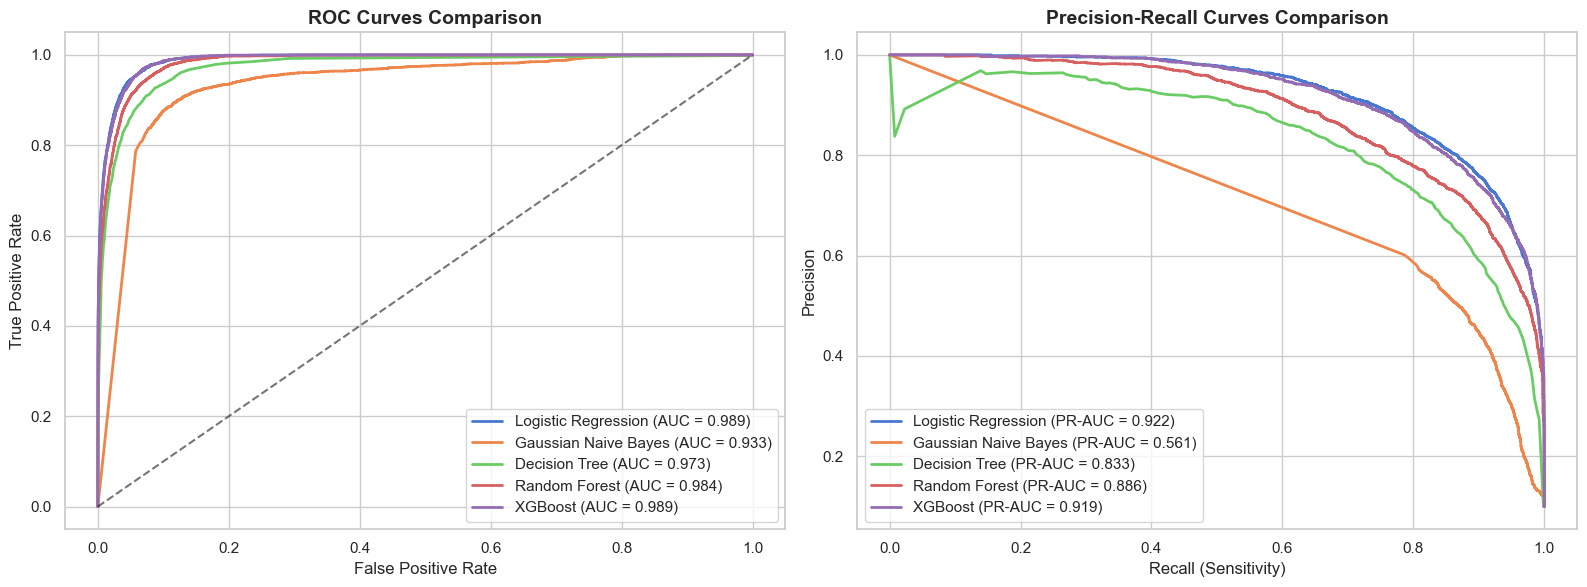

In [20]:
# Combined ROC and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6)
axes[0].set_title("ROC Curves Comparison", fontsize=14, fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc='lower right')

# Precision-Recall Curves
for name, y_prob in probabilities.items():
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, y_prob)
    pr_auc_score = average_precision_score(y_test, y_prob)
    axes[1].plot(rec_vals, prec_vals, label=f"{name} (PR-AUC = {pr_auc_score:.3f})", linewidth=2)

axes[1].set_title("Precision-Recall Curves Comparison", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

In [21]:
# Detailed Classification Reports
for name, y_pred in predictions.items():
    print(f"==================== {name} ====================")
    print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'Failed (1)'], digits=4))

==================== Logistic Regression ====================
              precision    recall  f1-score   support

 Healthy (0)     0.9784    0.9845    0.9814     36016
  Failed (1)     0.8511    0.8032    0.8264      3984

    accuracy                         0.9664     40000
   macro avg     0.9147    0.8938    0.9039     40000
weighted avg     0.9657    0.9664    0.9660     40000

==================== Gaussian Naive Bayes ====================
              precision    recall  f1-score   support

 Healthy (0)     0.9913    0.7970    0.8836     36016
  Failed (1)     0.3379    0.9365    0.4966      3984

    accuracy                         0.8109     40000
   macro avg     0.6646    0.8668    0.6901     40000
weighted avg     0.9262    0.8109    0.8451     40000

==================== Decision Tree ====================
              precision    recall  f1-score   support

 Healthy (0)     0.9693    0.9798    0.9745     36016
  Failed (1)     0.7974    0.7191    0.7562      3984

 

## 9. Feature Importance & Model Interpretability
Extracting top feature importances from the ensemble tree-based models (`Random Forest` and `XGBoost`) to understand the physical and operational drivers of battery failure.

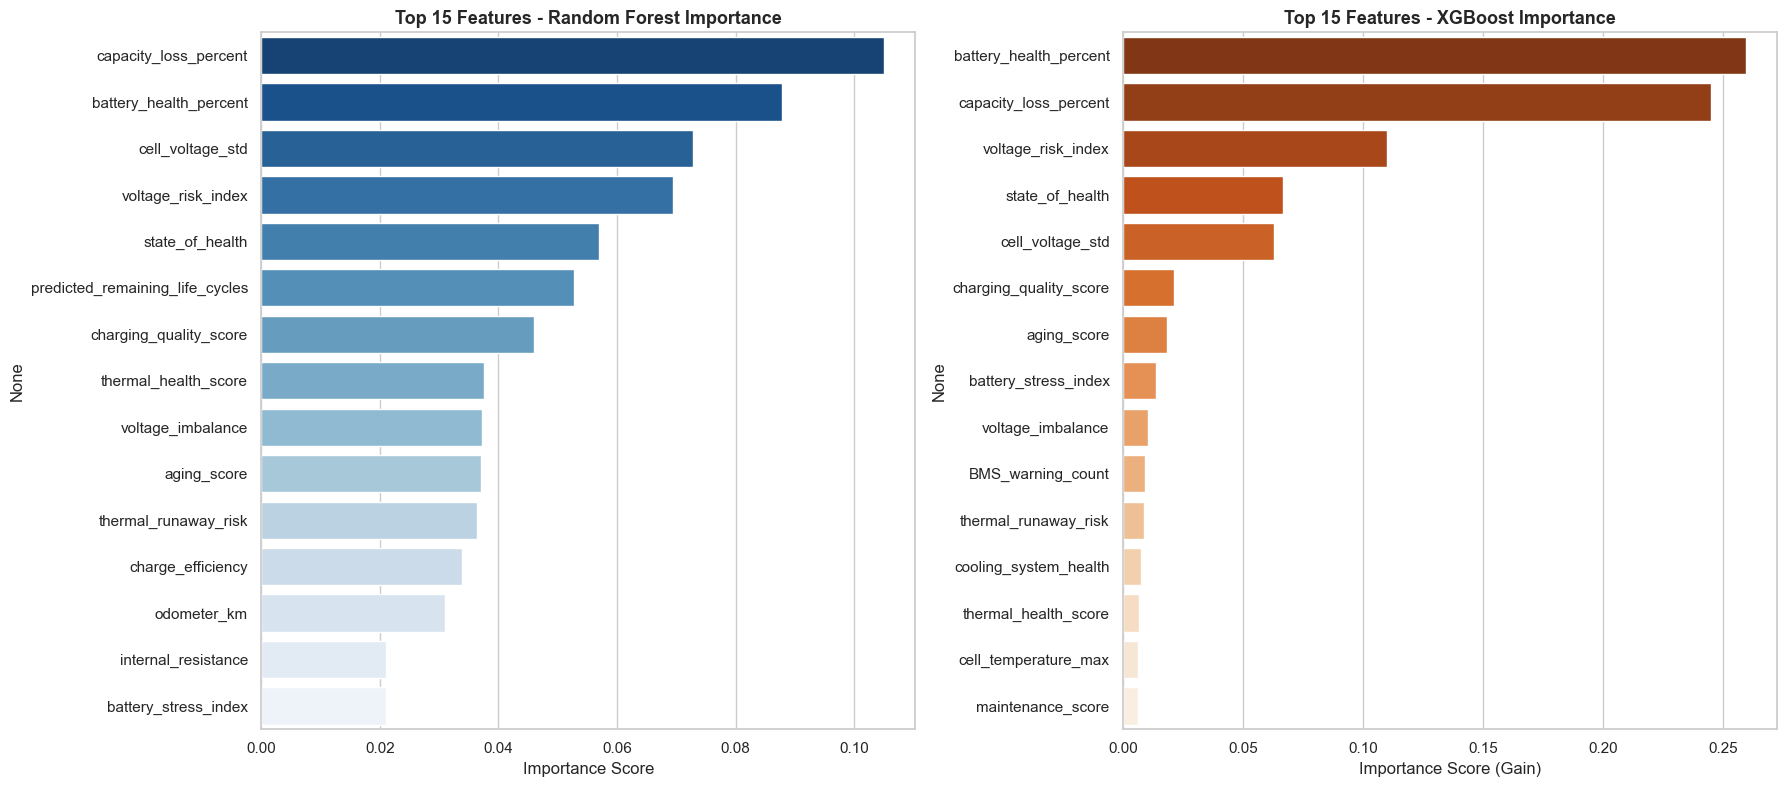

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Random Forest Feature Importance
rf_importances = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
sns.barplot(x=rf_importances.values, y=rf_importances.index, ax=axes[0], palette='Blues_r')
axes[0].set_title("Top 15 Features - Random Forest Importance", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Importance Score")

# XGBoost Feature Importance
xgb_importances = pd.Series(models['XGBoost'].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
sns.barplot(x=xgb_importances.values, y=xgb_importances.index, ax=axes[1], palette='Oranges_r')
axes[1].set_title("Top 15 Features - XGBoost Importance", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Importance Score (Gain)")

plt.tight_layout()
plt.show()

## 10. Operational Decision Threshold Optimization
In safety-critical automotive prognostics, a **False Negative** (undetected failing battery resulting in breakdown or fire) is substantially more dangerous and expensive than a **False Positive** (early diagnostic inspection).

By tuning the probability classification threshold on our best model (`XGBoost`), we can optimize the balance between Recall and Precision according to operational risk appetite.

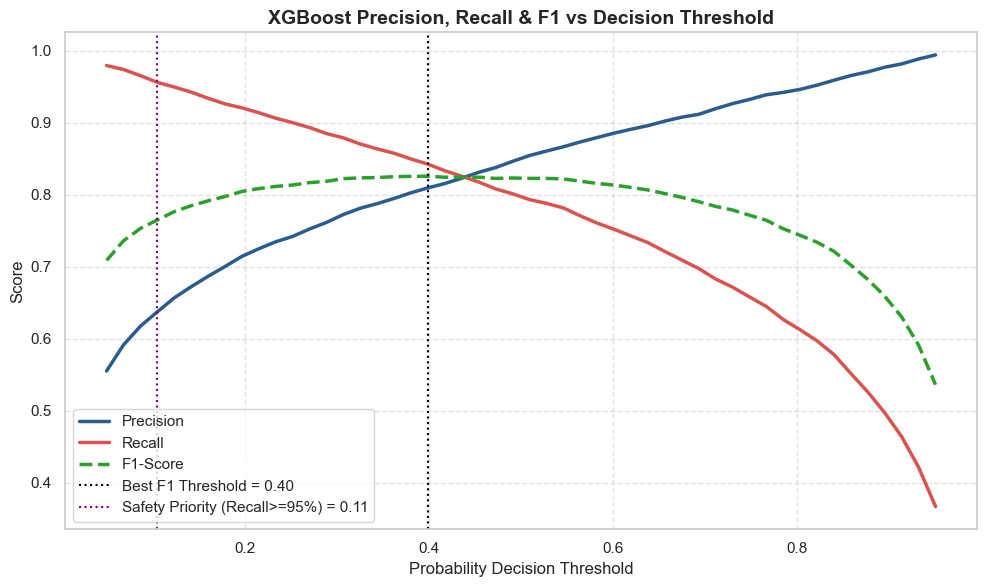

Optimal F1 Threshold: 0.40 -> Precision: 0.8095, Recall: 0.8424, F1: 0.8256
High Safety Recall Threshold: 0.11 -> Precision: 0.6374, Recall: 0.9558


In [23]:
# Threshold Tuning on XGBoost Probabilities
xgb_probs = probabilities['XGBoost']
thresholds = np.linspace(0.05, 0.95, 50)

prec_list, rec_list, f1_list = [], [], []

for t in thresholds:
    preds_t = (xgb_probs >= t).astype(int)
    prec_list.append(precision_score(y_test, preds_t, zero_division=0))
    rec_list.append(recall_score(y_test, preds_t, zero_division=0))
    f1_list.append(f1_score(y_test, preds_t, zero_division=0))

plt.figure(figsize=(10, 6))
plt.plot(thresholds, prec_list, label='Precision', color='#2b5c8f', linewidth=2.5)
plt.plot(thresholds, rec_list, label='Recall', color='#d9534f', linewidth=2.5)
plt.plot(thresholds, f1_list, label='F1-Score', color='#2ca02c', linewidth=2.5, linestyle='--')

# Optimal F1 threshold
best_idx = np.argmax(f1_list)
best_thresh = thresholds[best_idx]
plt.axvline(best_thresh, color='black', linestyle=':', label=f'Best F1 Threshold = {best_thresh:.2f}')

# High Recall Threshold for Safety (Recall >= 95%)
high_rec_thresh = thresholds[np.where(np.array(rec_list) >= 0.95)[0][-1]]
plt.axvline(high_rec_thresh, color='purple', linestyle=':', label=f'Safety Priority (Recall>=95%) = {high_rec_thresh:.2f}')

plt.title("XGBoost Precision, Recall & F1 vs Decision Threshold", fontsize=14, fontweight='bold')
plt.xlabel("Probability Decision Threshold")
plt.ylabel("Score")
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Optimal F1 Threshold: {best_thresh:.2f} -> Precision: {prec_list[best_idx]:.4f}, Recall: {rec_list[best_idx]:.4f}, F1: {f1_list[best_idx]:.4f}")
print(f"High Safety Recall Threshold: {high_rec_thresh:.2f} -> Precision: {precision_score(y_test, (xgb_probs>=high_rec_thresh).astype(int)):.4f}, Recall: {recall_score(y_test, (xgb_probs>=high_rec_thresh).astype(int)):.4f}")

## 11. Conclusion & Strategic Recommendations

### 📊 Summary of Findings
1. **Dataset Insights**:
   - The dataset contains 200,000 EV battery records with an approximate 10% failure rate (~90% healthy vs ~10% failed).
   - **Battery Chemistry**: LTO and LFP demonstrate superior thermal stability and drastically lower failure rates (<1.5%), whereas LMO (24.3%) and NCA (17.8%) show higher susceptibility to thermal and cycle stress.
   - **Fleet vs Private**: Commercial Fleet vehicles experience a failure rate of 26.3% compared to 3.6% in private vehicles, driven by high cycle counts, aggressive charging, and extensive daily mileage.
   - **Degradation Signals**: Capacity loss %, aging score, cell voltage standard deviation, and voltage imbalance are the strongest predictive signals of battery degradation.

2. **Model Performance**:
   - **Logistic Regression & XGBoost** achieved top-tier performance with **ROC-AUC > 0.988** and **F1-Score ~ 0.827**.
   - Tree-based ensembles (`XGBoost`, `Random Forest`) provide exceptional non-linear boundary separation while maintaining interpretability.

3. **Operational & Engineering Recommendations**:
   - **BMS Alert Thresholds**: Deploy real-time telematics alerts whenever `cell_voltage_std > 0.025V` or `voltage_imbalance > 30mV` in tandem with elevated temperature variance.
   - **Fast Charging Policy**: Dynamically throttle DC fast charging rates for packs exceeding 500 equivalent full cycles or displaying early capacity loss (>15%).
   - **Predictive Maintenance Scheduling**: Use lower probability decision thresholds (~0.35) for fleet operators to achieve >95% early failure detection, preventing on-road breakdowns and battery thermal events.